# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB20 — Where Do Identity and Context Combine? Locating the Source of the Interaction

**Track B · Follow-up to MB04, MB14, MB15, MB17 · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | The player's effect on Δ depends on the context (C4): the interaction is about as large as the player's own effect, and it lives inside the attention and MLP blocks (freezing them leaves only 0.04 nats, MB15). MB15 showed a random vector of the same norm produces as much interaction as a real player, so it comes from the network's non-linearity. **Which non-linearity?** The four MLPs' activation functions, the LayerNorms before them, or the final LayerNorm? |
| **Why it matters** | This is the most precise answer this model allows to RQ7 ("where and how do identity and context meet?"). A component whose context-dependent *gain* produces the interaction is where context changes how much the player matters. |
| **Idea** | To first order, the interaction equals how much the network's **sensitivity (gain) to the player change** differs between the two contexts. Give one component the **same gain in both contexts** (its gain from the own context) and see how much of the interaction disappears. A control gives the component its *own* gain in each context; that only adds linearisation error, so it should keep the interaction. |
| **Population** | P-player validation events with a context donor and a matched partner; estimation half primary, discovery half alongside. |
| **Status** | Follow-up after MB14–MB18; exploratory; not part of the MB12 lock. The plan is written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB20_plan.json`, `results/MB20_*`, `figures/MB20_*` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import torch.nn.functional as TF
from torch.func import jvp

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 97 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


## 1. Terms

| Term | Meaning here |
|---|---|
| **The 2 × 2** | Player A (own) or B (matched partner, or a fixed norm-matched random vector) × context X (own window) or Y (MB02 donor window with all four identity inputs written back). |
| **Interaction I** | Δ(A,X) − Δ(A,Y) − Δ(B,X) + Δ(B,Y): how much the effect of changing the player differs between the two contexts. |
| **Gain of a component** | How its output at the scored event responds to a small change of its input there: its Jacobian at the A-run. |
| **Own-context linearisation (control)** | In each B-run, the component's output = its A-run output in the same context + its gain at the A-run **of the same context** × (input change). Only linearisation error is added. |
| **Shared-gain linearisation (test)** | The same, but the gain is always the one at (A, X). The component then responds to the player change identically in both contexts, so it cannot create interaction. |
| **Interaction from the component** | Share of I lost under shared gain, minus the share lost under the own-context control. |
| **Components** | For each layer l: the whole MLP l (its LayerNorm + activation), its activation part only (LayerNorm left exact), its LayerNorm only (activation left exact); the final LayerNorm; and all four MLPs at once. Attention is left exact (MB14: heads carry ~1%). Everything acts at the scored position only, where the player change enters. |

## 2. The plan (written before any number)

In [4]:
PLAN = {
    "status": "follow-up after MB14-MB18; exploratory; not part of the MB12 lock",
    "factorial": "player A vs B (matched partner; fixed norm-matched random vector) x context X (own) vs Y (MB02 donor with the four identity inputs written back)",
    "components": ["MLP l whole (l = 0..3)", "MLP l activation part only", "MLP l LayerNorm only", "final LayerNorm", "all four MLPs whole"],
    "manipulations": {"own": "B-runs: output = A-run output (same context) + Jacobian at the A-run of the same context x input change",
                      "shared": "B-runs: output = A-run output (same context) + Jacobian at (A, X) x input change"},
    "measure": "interaction retained = pooled sign-aligned sum(sign(I) * I_manipulated) / sum(|I|), I from the exact network; match-resampled CIs",
    "attribution": "interaction from a component = retained(own) - retained(shared), paired over events, with CI",
    "reading_rule": ("a component is called a SOURCE of the interaction if retained(own) CI low >= 0.8 (the linearisation itself is harmless) AND "
                     "retained(own) - retained(shared) CI low > 0.2; the interaction is called ACCOUNTED FOR by the MLPs if all four MLPs with shared gain retain < 0.2"),
    "half": "estimation primary, discovery reported alongside",
    "player_B": "matched partner primary; random vector reported to check the answer is the same"
}
plan_path = OUT / "config" / "MB20_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB20_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB20_plan.json
{
 "status": "follow-up after MB14-MB18; exploratory; not part of the MB12 lock",
 "factorial": "player A vs B (matched partner; fixed norm-matched random vector) x context X (own) vs Y (MB02 donor with the four identity inputs written back)",
 "components": [
  "MLP l whole (l = 0..3)",
  "MLP l activation part only",
  "MLP l LayerNorm only",
  "final LayerNorm",
  "all four MLPs whole"
 ],
 "manipulations": {
  "own": "B-runs: output = A-run output (same context) + Jacobian at the A-run of the same context x input change",
  "shared": "B-runs: output = A-run output (same context) + Jacobian at (A, X) x input change"
 },
 "measure": "interaction retained = pooled sign-aligned sum(sign(I) * I_manipulated) / sum(|I|), I from the exact network; match-resampled CIs",
 "attribution": "interaction from a component = retained(own) - retained(shared), paired over events, with CI",
 "reading_rule": "a component is called a SOURCE of the interaction if retained(own

## 3. The linearised components

Each manipulation is implemented as a pair of hooks. The hook on the component's input (`mlp_in_l` or `final_resid`) records the input of the current run. The hook on its output (`mlp_out_l` or `final_normalised`) replaces the output at the scored position by the linearised value. Jacobian-vector products are computed exactly with `torch.func.jvp`.

**Built-in check.** With player B equal to player A, every linearisation must reproduce the exact network: the input change is zero.

In [5]:
units = p_player[p_player["donor_window"].notna()].copy()
units["donor_window"] = units["donor_window"].astype(int)
units["partner"] = [partner_of.get(p, -1) for p in units["player"]]
units = units[units["partner"] > 0].reset_index(drop=True)
print(f"units: {len(units)} (estimation {int((units.half == 'estimation').sum())})")
D_MODEL = MODEL.ln_final.weight.shape[0]


def mlp_whole(layer):
    block = MODEL.blocks[layer]
    return lambda x: block.mlp.output_layer(TF.gelu(block.mlp.input_layer(block.ln_mlp(x))))


def mlp_activation(layer):
    block = MODEL.blocks[layer]
    return lambda u: block.mlp.output_layer(TF.gelu(block.mlp.input_layer(u)))


def mlp_layernorm(layer):
    return MODEL.blocks[layer].ln_mlp


COMPONENTS = {}
for l in range(N_LAYERS):
    COMPONENTS[f"L{l} MLP (whole)"] = [("mlp", l, "whole")]
    COMPONENTS[f"L{l} MLP activation only"] = [("mlp", l, "activation")]
    COMPONENTS[f"L{l} MLP LayerNorm only"] = [("mlp", l, "layernorm")]
COMPONENTS["final LayerNorm"] = [("final", None, "layernorm")]
COMPONENTS["all four MLPs (whole)"] = [("mlp", l, "whole") for l in range(N_LAYERS)]


def site_names(kind, layer):
    return (f"mlp_in_{layer}", f"mlp_out_{layer}") if kind == "mlp" else ("final_resid", "final_normalised")


def linearised_value(kind, layer, part, x_now, x_ref, x_gain):
    """Linearised output of a component at the scored rows. x_* are [N, D] inputs of the component."""
    if kind == "final":
        ln = MODEL.ln_final
        return ln(x_ref) + jvp(ln, (x_gain,), (x_now - x_ref,))[1]
    if part == "whole":
        f = mlp_whole(layer)
        return f(x_ref) + jvp(f, (x_gain,), (x_now - x_ref,))[1]
    ln, g = mlp_layernorm(layer), mlp_activation(layer)
    if part == "activation":
        u_now, u_ref, u_gain = ln(x_now), ln(x_ref), ln(x_gain)
        return g(u_ref) + jvp(g, (u_gain,), (u_now - u_ref,))[1]
    # LayerNorm only: the LayerNorm is linearised, the activation stays exact
    return g(ln(x_ref) + jvp(ln, (x_gain,), (x_now - x_ref,))[1])


def linearise_replace(spec, positions, refs, gains):
    """replace-dict for one B-run: spec = list of (kind, layer, part); refs/gains: {input site: [N, D] tensors}."""
    rows = torch.arange(len(positions), device=DEVICE)
    store, replace = {}, {}
    for kind, layer, part in spec:
        in_site, out_site = site_names(kind, layer)

        def record(value, in_site=in_site):
            store[in_site] = value[rows, positions]
            return value

        def edit(value, kind=kind, layer=layer, part=part, in_site=in_site):
            new = value.clone()
            new[rows, positions] = linearised_value(kind, layer, part, store[in_site], refs[in_site], gains[in_site])
            return new
        replace[in_site] = record
        replace[out_site] = edit
    return replace


INPUT_SITES = [f"mlp_in_{l}" for l in range(N_LAYERS)] + ["final_resid"]
FROZEN = [f"attn_out_{l}" for l in range(N_LAYERS)] + [f"mlp_out_{l}" for l in range(N_LAYERS)]


@torch.no_grad()
def factorial_runs(table, second, seed=0, check=False):
    """Per-event interaction for the exact network, the floor (all blocks frozen at the A-run), and every component x manipulation."""
    generator = torch.Generator().manual_seed(seed)
    keys = ["exact", "floor"] + [f"{name} | {mode}" for name in COMPONENTS for mode in ["own", "shared"]]
    out = {key: [] for key in keys}
    for part_rows in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part_rows]
        x_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
        y_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
        positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
        rows = torch.arange(len(positions), device=DEVICE)
        y_inputs = interventions.write_identity(y_inputs, x_inputs, positions, IDENTITY_FEATURES)
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE)
        a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        d = lambda logits: mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_id)
        direction = torch.randn((len(chunk), D_MODEL), generator=generator).to(DEVICE)
        direction = direction / direction.norm(dim=-1, keepdim=True)

        def fixed_vector(value):
            new = value.clone()
            new[rows, positions] = direction * value[rows, positions].norm(dim=-1, keepdim=True)
            return new

        def b_run(context):
            if check:
                return context, {}
            if second == "partner":
                return interventions.set_feature(context, "player", positions, torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE)), {}
            return context, {"factor_player": fixed_vector}

        a_logits, a_cache, b_inputs, b_base = {}, {}, {}, {}
        for name, context in [("X", x_inputs), ("Y", y_inputs)]:
            a_logits[name], a_cache[name] = hooks.forward(MODEL, context, capture=INPUT_SITES + FROZEN)
            b_inputs[name], b_base[name] = b_run(context)
        refs = {name: {site: a_cache[name][site][rows, positions] for site in INPUT_SITES} for name in ["X", "Y"]}

        def interaction(b_x, b_y):
            return d(a_logits["X"]) - d(a_logits["Y"]) - b_x + b_y

        exact_b = {name: d(hooks.forward(MODEL, b_inputs[name], replace=b_base[name])[0]) for name in ["X", "Y"]}
        out["exact"].append(interaction(exact_b["X"], exact_b["Y"]))
        floor_b = {name: d(hooks.forward(MODEL, b_inputs[name], replace={**b_base[name], **{s: (lambda v, kept=a_cache[name][s]: kept) for s in FROZEN}})[0])
                   for name in ["X", "Y"]}
        out["floor"].append(interaction(floor_b["X"], floor_b["Y"]))
        for component, spec in COMPONENTS.items():
            for mode in ["own", "shared"]:
                values = {}
                for name in ["X", "Y"]:
                    gains = refs[name] if mode == "own" else refs["X"]
                    replace = {**b_base[name], **linearise_replace(spec, positions, refs[name], gains)}
                    values[name] = d(hooks.forward(MODEL, b_inputs[name], replace=replace)[0])
                out[f"{component} | {mode}"].append(interaction(values["X"], values["Y"]))
    return {key: np.concatenate(values) for key, values in out.items()}


check = factorial_runs(units.iloc[:min(len(units), 2 * BATCH)], "partner", check=True)
worst = max(float(np.abs(values).max()) for key, values in check.items() if key != "floor")
print(f"check with B = A: largest interaction under any linearisation {worst:.2e} (must be ~0)")
assert worst < 1e-3, "BLOCKED: a linearisation does not reproduce the exact network when the player is unchanged."

units: 1716 (estimation 529)


check with B = A: largest interaction under any linearisation 4.77e-06 (must be ~0)


## 4. How much interaction survives each manipulation

In [6]:
RUNS = {second: factorial_runs(units, second) for second in ["partner", "random vector"]}
rows_out = []
for second, runs in RUNS.items():
    for half in ["estimation", "discovery"]:
        keep = (units.half == half).to_numpy()
        m = units["match_id"].to_numpy()[keep]
        exact = runs["exact"][keep]
        row_floor = mi_metrics.pooled_recovery(runs["floor"][keep], exact, m, N_BOOT)
        rows_out.append({"player B": second, "half": half, "component": "(all blocks frozen: floor)", "own: retained": np.nan,
                         "shared: retained": row_floor["recovery"], "mean |I| exact": float(np.abs(exact).mean())})
        for component in COMPONENTS:
            own = runs[f"{component} | own"][keep]
            shared = runs[f"{component} | shared"][keep]
            r_own = mi_metrics.pooled_recovery(own, exact, m, N_BOOT)
            r_shared = mi_metrics.pooled_recovery(shared, exact, m, N_BOOT)
            lost = mi_metrics.summarise(mi_metrics.aligned(own - shared, exact) / np.abs(exact).mean(), m, N_BOOT)
            source = (r_own["ci_low"] >= 0.8) and (lost["ci_low"] > 0.2)
            rows_out.append({"player B": second, "half": half, "component": component,
                             "own: retained": r_own["recovery"], "own CI low": r_own["ci_low"], "own CI high": r_own["ci_high"],
                             "shared: retained": r_shared["recovery"], "shared CI low": r_shared["ci_low"], "shared CI high": r_shared["ci_high"],
                             "interaction from this component": lost["mean"], "CI low": lost["ci_low"], "CI high": lost["ci_high"],
                             "SOURCE (plan rule)": source, "mean |I| exact": float(np.abs(exact).mean())})
sources = pd.DataFrame(rows_out)
sources.to_csv(OUT / "results" / "MB20_interaction_sources.csv", index=False)
show = ["component", "own: retained", "shared: retained", "interaction from this component", "CI low", "CI high", "SOURCE (plan rule)"]
for second in RUNS:
    print(f"\nplayer B = {second}, estimation half:")
    print(sources[(sources["player B"] == second) & (sources.half == "estimation")][show].round(3).to_string(index=False))
all_mlps = sources[(sources["player B"] == "partner") & (sources.half == "estimation") & (sources.component == "all four MLPs (whole)")].iloc[0]
print(f"\nall four MLPs with shared gain retain {all_mlps['shared: retained']:.3f} of the interaction "
      f"-> accounted for by the MLPs (plan rule: < 0.2): {all_mlps['shared: retained'] < 0.2}")


player B = partner, estimation half:
                 component  own: retained  shared: retained  interaction from this component  CI low  CI high SOURCE (plan rule)
(all blocks frozen: floor)            NaN             0.011                              NaN     NaN      NaN                NaN
            L0 MLP (whole)          0.927             0.822                            0.105   0.041    0.164              False
    L0 MLP activation only          0.993             0.879                            0.114   0.066    0.153              False
     L0 MLP LayerNorm only          0.937             0.948                           -0.010  -0.062    0.032              False
            L1 MLP (whole)          0.961             0.736                            0.225   0.160    0.266              False
    L1 MLP activation only          0.989             0.805                            0.183   0.128    0.218              False
     L1 MLP LayerNorm only          0.976             0.957

## 5. The picture

For each component: how much of the interaction it creates (own minus shared), for the real partner and for the random vector. Bars are on the estimation half with 95% intervals.

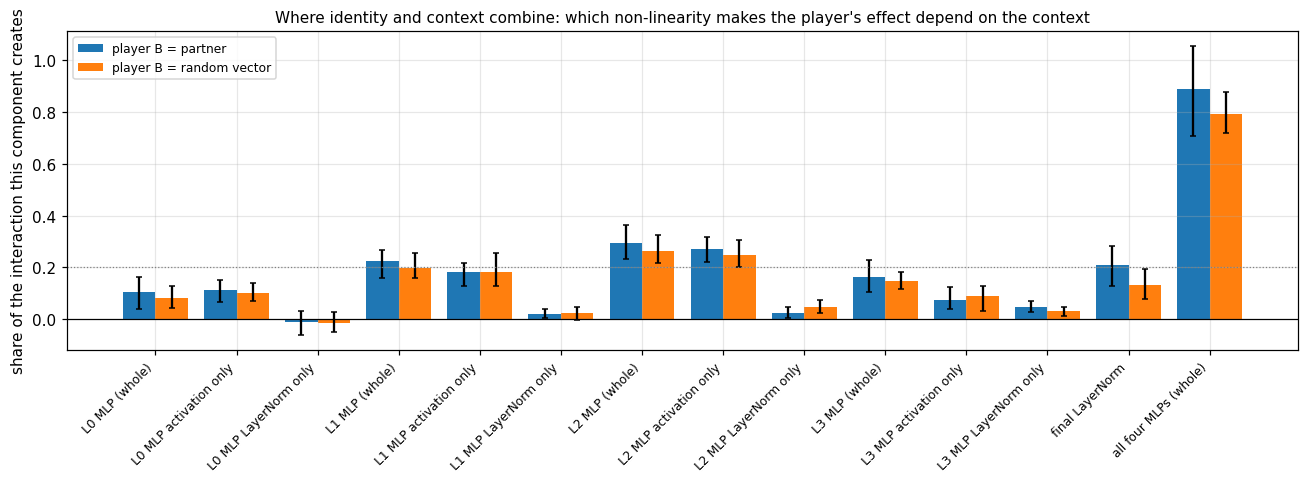

In [7]:
fig, axis = plt.subplots(figsize=(12, 4.5))
names = list(COMPONENTS)
x = np.arange(len(names))
for k, second in enumerate(RUNS):
    block = sources[(sources["player B"] == second) & (sources.half == "estimation")].set_index("component").loc[names]
    axis.bar(x + (k - 0.5) * 0.4, block["interaction from this component"], 0.4, label=f"player B = {second}",
             yerr=[block["interaction from this component"] - block["CI low"], block["CI high"] - block["interaction from this component"]], capsize=2)
axis.set_xticks(x); axis.set_xticklabels(names, rotation=45, ha="right", fontsize=8); axis.axhline(0, color="black", linewidth=0.8)
axis.axhline(0.2, color="grey", linestyle=":", linewidth=0.8)
axis.set_ylabel("share of the interaction this component creates")
axis.set_title("Where identity and context combine: which non-linearity makes the player's effect depend on the context", fontsize=10)
axis.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB20_interaction_sources.png", bbox_inches="tight", dpi=150); plt.show()

**How to read it.**

- A tall bar for **one MLP's activation** means the context changes how much the player matters mainly by moving that MLP's units into a different part of their activation curve: a gating effect located in that layer.
- A tall bar for a **LayerNorm** means it acts through normalisation: a large context signal shrinks the relative size of the player signal.
- If several MLPs each contribute a little and "all four MLPs" removes most of it, the combination is **spread along the chain**.
- If the random-vector bars match the partner bars, the combining mechanism does not distinguish learned player content from any other change of the player input (MB15 Q3).

## 6. Summary and integrity

In [8]:
summary = {"status": PLAN["status"], "sources": sources.to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB20_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB20_summary.json": OUT / "results" / "MB20_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB20", "experiment": "source of the identity x context interaction (shared-gain linearisation)",
                                "seed": PRIMARY_SEED, "run_mode": RUN_MODE})
print(sources[(sources["player B"] == "partner") & (sources.half == "estimation") & sources["SOURCE (plan rule)"].fillna(False).astype(bool)]
      [["component", "interaction from this component", "CI low", "CI high"]].round(3).to_string(index=False) or "no single component passes the SOURCE rule")

             component  interaction from this component  CI low  CI high
        L2 MLP (whole)                            0.295   0.231    0.365
L2 MLP activation only                            0.271   0.220    0.317
 all four MLPs (whole)                            0.888   0.707    1.055


In [9]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 99
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: